# Wikipedia recommender system: report

*Information Retrieval project, Poznan University of Technology.*

The system recommends English Wikipedia articles similar to a collection of visited ones. **Input:** a
list of article titles or URLs. **Output:** a ranked list of corpus articles (title and link) with a score
in [0, 1], and an explanation of each score.

```text
Stage 1  crawler/        Vital articles lists ──► 2,200 articles ──► data/raw/articles_raw.parquet
Stage 2  preprocessing/  clean ► tokenize ► lemmatize + stem ──► data/processed/articles_processed.parquet
Stage 3  recommender/    TF-IDF + embeddings ► similarity ► interests ► top-k with scores
Stage 5  visualization/  corpus statistics and score breakdowns (this report)
```

Every chart below is computed from the data when the notebook runs; `reports/figures/` keeps a copy of
each. To try the recommender with your own articles, use `notebooks/02_recommender_demo.ipynb` or
`python -m wiki_recommender.recommender "Dog" "Cat"`.

**Contents**
1. Crawling and scraping
2. Preprocessing: stemming and lemmatization
3. Scoring: how articles are recommended
4. Statistics of the database
5. Examples of recommendations, with explanations
6. Evaluation and limitations

In [1]:
import os
from pathlib import Path

# Data paths are relative to the repository root, so run from there wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from wiki_recommender.recommender import Recommender
from wiki_recommender.visualization import breakdown, corpus, evaluation
from wiki_recommender.visualization.style import apply_style, save

warnings.filterwarnings("ignore")
apply_style()
pd.set_option("display.precision", 3)

recommender = Recommender.load()
model = recommender.model
frame = corpus.load_corpus_frame()
raw_stats = corpus.load_stats(corpus.RAW_STATS_PATH)
stats = corpus.load_stats(corpus.PROCESSED_STATS_PATH)
representation_eval = evaluation.load_eval(evaluation.REPRESENTATION_EVAL_PATH)
recommender_eval = evaluation.load_eval(evaluation.RECOMMENDER_EVAL_PATH)


def show(figure, name):
    """Display a chart and keep a copy in reports/figures."""
    figure = getattr(figure, "figure", figure)
    save(figure, name)
    plt.show()


def as_table(result) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "rank": r.rank,
                "title": r.title,
                "score": r.score,
                "text": r.signal_contributions["text"],
                "embedding": r.signal_contributions["embedding"],
                "compared with": ", ".join(r.interest),
                "shared terms": ", ".join(r.shared_terms[:4]),
            }
            for r in result.recommendations
        ]
    ).set_index("rank")

## 1. Crawling and scraping

**Source.** Articles come from English Wikipedia's
[Vital articles](https://en.wikipedia.org/wiki/Wikipedia:Vital_articles) lists, levels 4 and 5, which sort
about 50,000 important articles into 11 topics and thousands of subsections. Using them instead of a
random walk over links gives a corpus that is broad, made of substantial articles, and labelled: each
article carries its topic and subsection, which the evaluation later uses as ground truth.

**Selection.** Each topic gets the same quota of 200 articles:
1. articles of levels 1-3 (such as *World War II* or *Dog*) are always taken;
2. the rest is a 60/40 mix of level 4 articles and narrower level 5 ones, which add niche subjects;
3. within a level, subsections take turns (round-robin), shuffled with a fixed seed so no
   subsection or alphabetical prefix can crowd out the others.

**Filtering.** Disambiguation pages, redirects to an article already collected, link collections
(`List of ...`, `Outline of ...`), pages outside the main namespace and pages under 100 words are rejected.

**Scraping.** Each page is fetched with the MediaWiki `action=parse` API and its HTML is reduced to
running prose: infoboxes, tables, navigation templates, figures, formulas, pronunciation guides,
citation markers and trailing sections (*See also*, *References*, *External links*) are removed. The
title, URL, lead section, section headings, categories and outgoing links are stored separately.

**Politeness.** A descriptive `User-Agent`, at least 0.25 s between requests, `maxlag=5` (the crawler
yields when Wikipedia's servers are busy) and exponential backoff on errors or `Retry-After`. An
interrupted crawl resumes from a checkpoint.

In [2]:
words = raw_stats["words"]
pd.DataFrame(
    {
        "articles": [raw_stats["articles"]],
        "candidates in the lists": [raw_stats["candidates_discovered"]],
        "topics": [len(raw_stats["per_topic"])],
        "subsections": [raw_stats["distinct_seed_sections"]],
        "categories": [raw_stats["distinct_categories"]],
        "words in total": [words["total"]],
        "median words per article": [words["median"]],
    }
).T.rename(columns={0: "value"}).style.format("{:,}")

,value
articles,"2,200"
candidates in the lists,"49,747"
topics,11
subsections,"1,329"
categories,"15,638"
words in total,"13,074,491"
median words per article,"5,196"


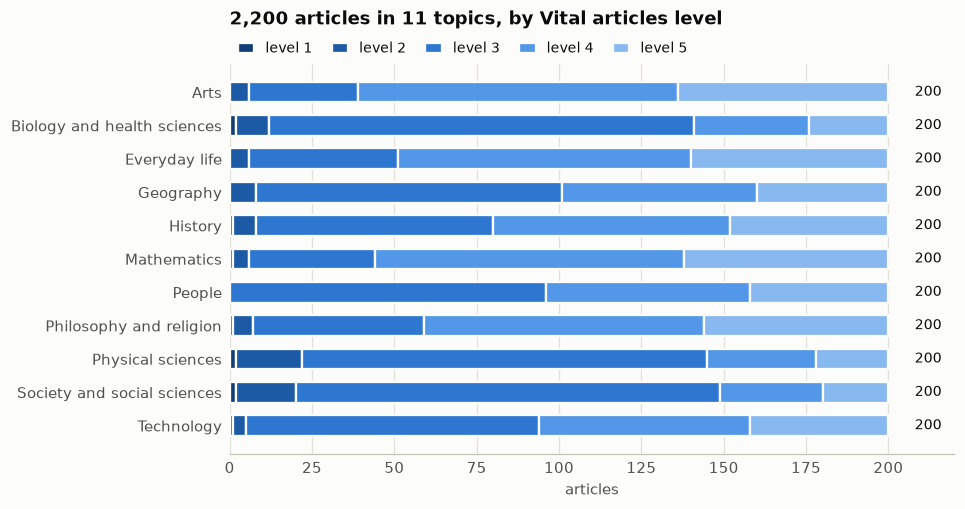

In [3]:
show(corpus.plot_topic_composition(frame), "topic_composition")

Every topic holds exactly 200 articles. The share of level 5 articles differs between topics because
the lists differ: Mathematics has fewer level 1-4 articles, so more of its quota comes from level 5.

## 2. Preprocessing: stemming and lemmatization

**Cleaning.** The crawler already removes most markup. This stage removes what is left: URLs, stray
HTML tags, `[[ ]]` and `{{ }}` brackets, unfilled template parameters and repeated whitespace.
Categories that describe Wikipedia's own maintenance (*Articles with short description*, *Living
people*) are dropped, because they say nothing about the subject.

**Tokens, lemmas and stems.** Every article is tokenized once with spaCy (`en_core_web_sm`). Each word
that passes one shared filter yields both a **lemma** (spaCy, part-of-speech aware) and a **stem**
(NLTK Snowball), so the two token lists stay aligned word for word:

* case and accents are folded (*Müller* = *Muller*);
* stopwords, punctuation, numbers, ordinals (*19th*) and year ranges are removed; all-caps acronyms
  (*US*, *WHO*) are kept;
* tokens must be Latin-script, 2 to 40 characters long and contain a letter (`covid-19` survives).

**Repairing lemmas.** spaCy guesses the lemma of an unknown word by stripping a plural ending, which
gives `cryptocurrencie`, or turns *series* into `serie`. After the whole corpus is read, such a guess is
kept only if the corpus itself contains the singular at least a tenth as often as the plural:
*cryptocurrencies* becomes `cryptocurrency`, while *series* and *species* stay whole. 4,413 lemmas were
repaired this way.

**Stored form.** `articles_processed.parquet` keeps, for each article, the lemmas and the stems of its
text, its *definition* (the first full lead paragraph, which says what the subject is), the length of
its lead, and its lemmatized categories.

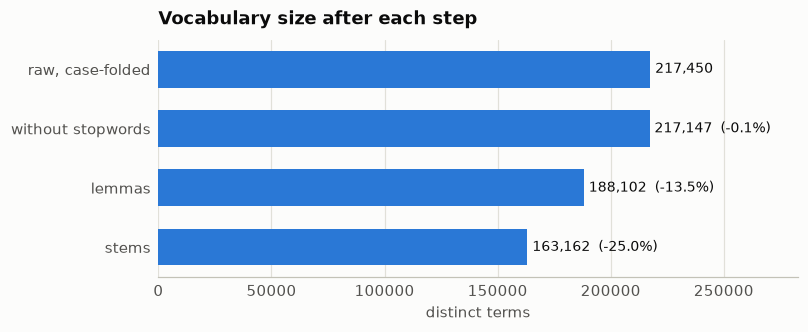

In [4]:
show(corpus.plot_vocabulary(stats), "vocabulary")

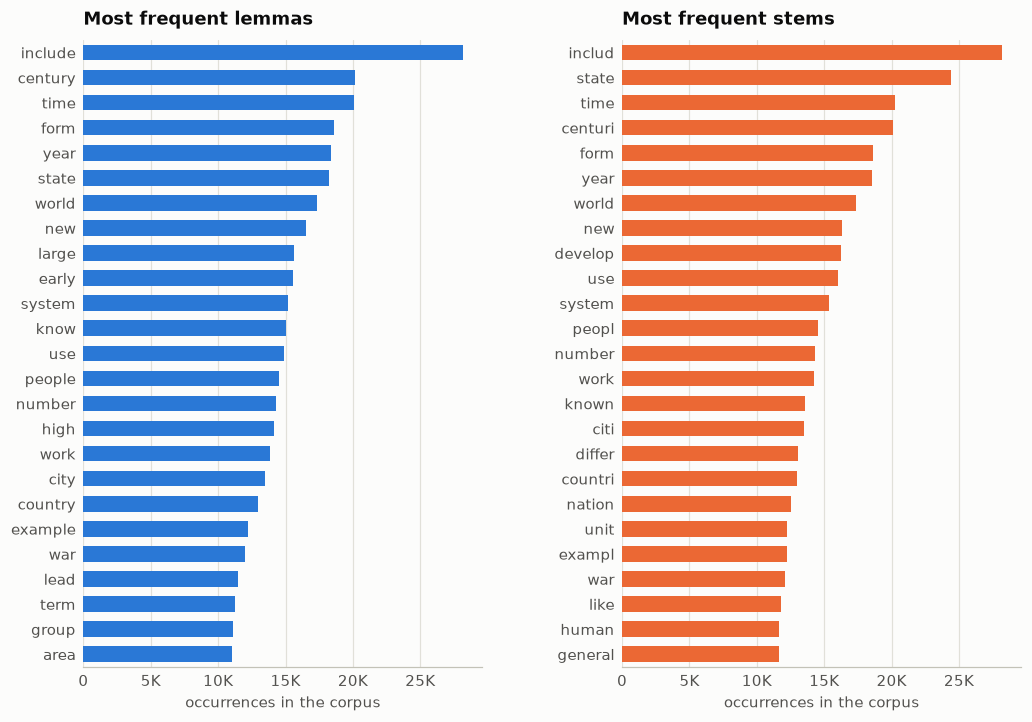

In [5]:
show(corpus.plot_top_words(stats, 25), "top_words")

**Lemmas or stems?** Stemming shrinks the vocabulary more, but it also merges unrelated words: *universe*
and *university* share the stem `univers`, and *united* and *unit* share `unit`, which is why `unit`
ranks far higher among stems than `united` among lemmas. Lemmas are real words, which keeps the term
charts and score explanations readable (`university`, not `univers`).

The choice was also measured. Each representation is judged by how often an article's 10 nearest
neighbours are related to it by signals that do not come from its text: the same Vital articles
subsection, and a shared category from a held-out half of the categories. Settings were chosen on one
half of the articles and measured on the other half (1,093 articles).

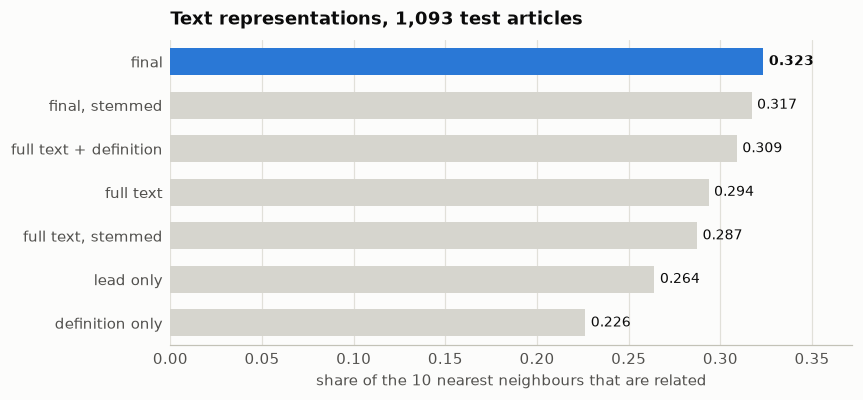

In [6]:
show(evaluation.plot_representation_eval(representation_eval), "representation_eval")

In [7]:
comparisons = pd.DataFrame(representation_eval["comparisons_on_test"]).T
comparisons.columns = ["difference", "95% low", "95% high"]
comparisons

,difference,95% low,95% high
final vs full text,0.030,1.879e-02,0.041
final vs definition only,0.097,8.174e-02,0.112
final vs lead only,0.059,4.666e-02,0.071
full text vs definition only,0.067,4.769e-02,0.085
"final vs final, stemmed",0.006,1.225e-03,0.011
"full text vs full text, stemmed",0.006,8.008e-04,0.012


Lemmas beat stems by a small margin, but consistently (the paired bootstrap interval excludes zero), so
**lemmas are the canonical representation**. Adding the definition again (weight 0.5) and the category
tokens (weight 0.25) improves on the full text alone by +0.030. The final text vector of an article is

$$\mathbf{t} = \operatorname{norm}\big(\operatorname{norm}(\text{tfidf}(\text{article}) + 0.5\,\text{tfidf}(\text{definition}))
\;\Vert\; 0.25\,\text{tfidf}(\text{categories})\big)$$

with sublinear TF ($1 + \log tf$), IDF fitted on the corpus, terms in at least two articles, and
$\Vert$ the concatenation of the word and category features.

## 3. Scoring: how articles are recommended

### 3.1 Similarity of two articles

Two signals compare a visited article $v$ with a candidate $c$. Each is a cosine similarity in [0, 1]:

| Signal | Representation | Weight |
| :--- | :--- | ---: |
| Text | the TF-IDF vector $\mathbf{t}$ of section 2 | 0.60 |
| Embedding | `BAAI/bge-small-en-v1.5` sentence embedding of the title and the first 150 words | 0.40 |

$$s(v, c) = 0.60\,\cos_{\text{text}}(v, c) + 0.40\,\max\big(0, \cos_{\text{emb}}(v, c)\big)$$

The weights sum to 1, so $s(v, c) \in [0, 1]$. Text and embeddings complement each other: TF-IDF
matches exact terms and names, the embedding matches meaning when the words differ.

### 3.2 From a history to one score

A history $V = \{v_1, \dots, v_m\}$ is first split into **interests**: visited articles are clustered
with average linkage on $1 - s(v_i, v_j)$, and two stay together while their mean similarity is at least
$t = 0.3$. For a candidate $c \notin V$ and an interest $I$:

$$\text{score}_I(c) = \frac{1}{|I|} \sum_{v \in I} s(v, c), \qquad \text{score}(c) = \max_I\, \text{score}_I(c)$$

The top-$k$ list is shared between interests in proportion to their size (each interest contributes its
best candidates), visited articles are never recommended, and the list is sorted by score. With a single
interest this is the plain mean, which ranks exactly like the centroid of the visited articles.

Why not just the mean? For a history about two unrelated subjects, the mean favours articles that sit
between both and match neither well. Section 6 measures this.

### 3.3 Explaining a score

Because the score is a mean of weighted cosines, it splits exactly into parts. With $\mathbf{u}$ the
mean text vector of the interest:

$$\text{score}(c) = \underbrace{\sum_{\text{terms } w} 0.60\, u_w\, c_w}_{\text{shared terms}}
+ 0.40\,\overline{\cos}_{\text{emb}}
= \frac{1}{|I|}\sum_{v \in I} s(v, c)$$

The first form gives the **waterfall** charts (which shared words and which signals add up to the
score), the second the **per-visited-article** charts (how much each visited article contributes).

## 4. Statistics of the database

### 4.1 Article length

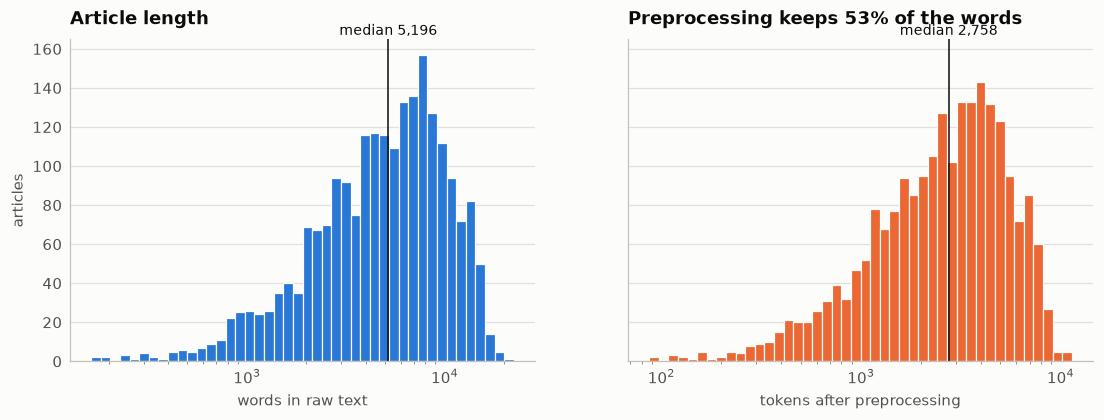

In [8]:
show(corpus.plot_length_histograms(frame), "length_histograms")

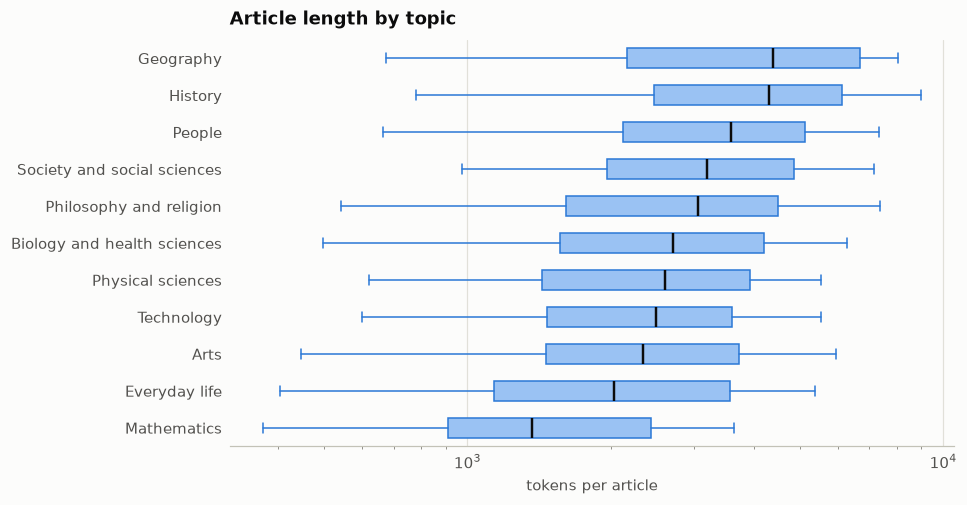

In [9]:
show(corpus.plot_length_by_topic(frame), "length_by_topic")

In [10]:
frame[["word_count", "token_count", "lead_token_count", "categories", "outlinks", "sections"]].describe(
    percentiles=[0.1, 0.5, 0.9]
).T[["mean", "min", "10%", "50%", "90%", "max"]].round(0)

,mean,min,10%,50%,90%,max
word_count,5943.0,163.0,1545.0,5196.0,11599.0,22432.0
token_count,3151.0,87.0,793.0,2758.0,6162.0,11411.0
lead_token_count,164.0,8.0,56.0,154.0,285.0,540.0
categories,9.0,1.0,2.0,5.0,20.0,117.0
outlinks,254.0,9.0,62.0,211.0,491.0,1456.0
sections,25.0,0.0,8.0,23.0,45.0,96.0


Lengths are roughly log-normal: the median article has about 5,200 words, and the longest about 22,400.
Preprocessing keeps about half of the words; most of the rest are stopwords. Biographies and history
articles are the longest, mathematics articles the shortest.

### 4.2 Most important terms

The most frequent lemmas (section 2) are general words such as *include*, *time* and *year*. TF-IDF
weights tell more: below, the highest mean weight over all articles (left), and for each topic the words
that stand out most against the rest of the corpus.

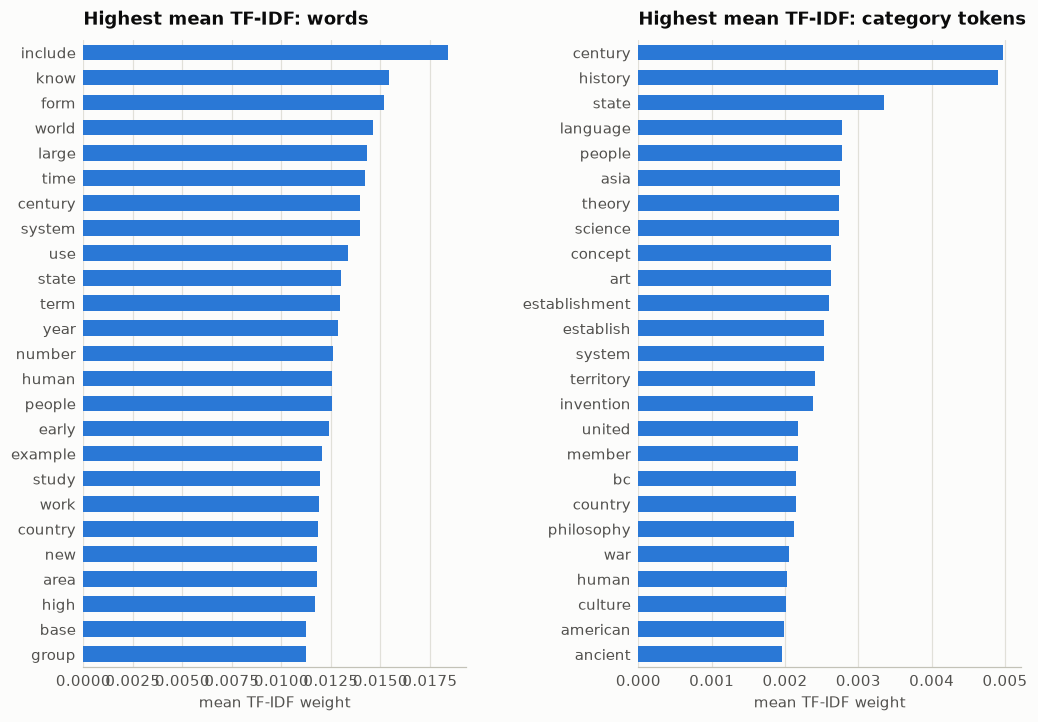

In [11]:
show(corpus.plot_top_tfidf(model, 25), "top_tfidf")

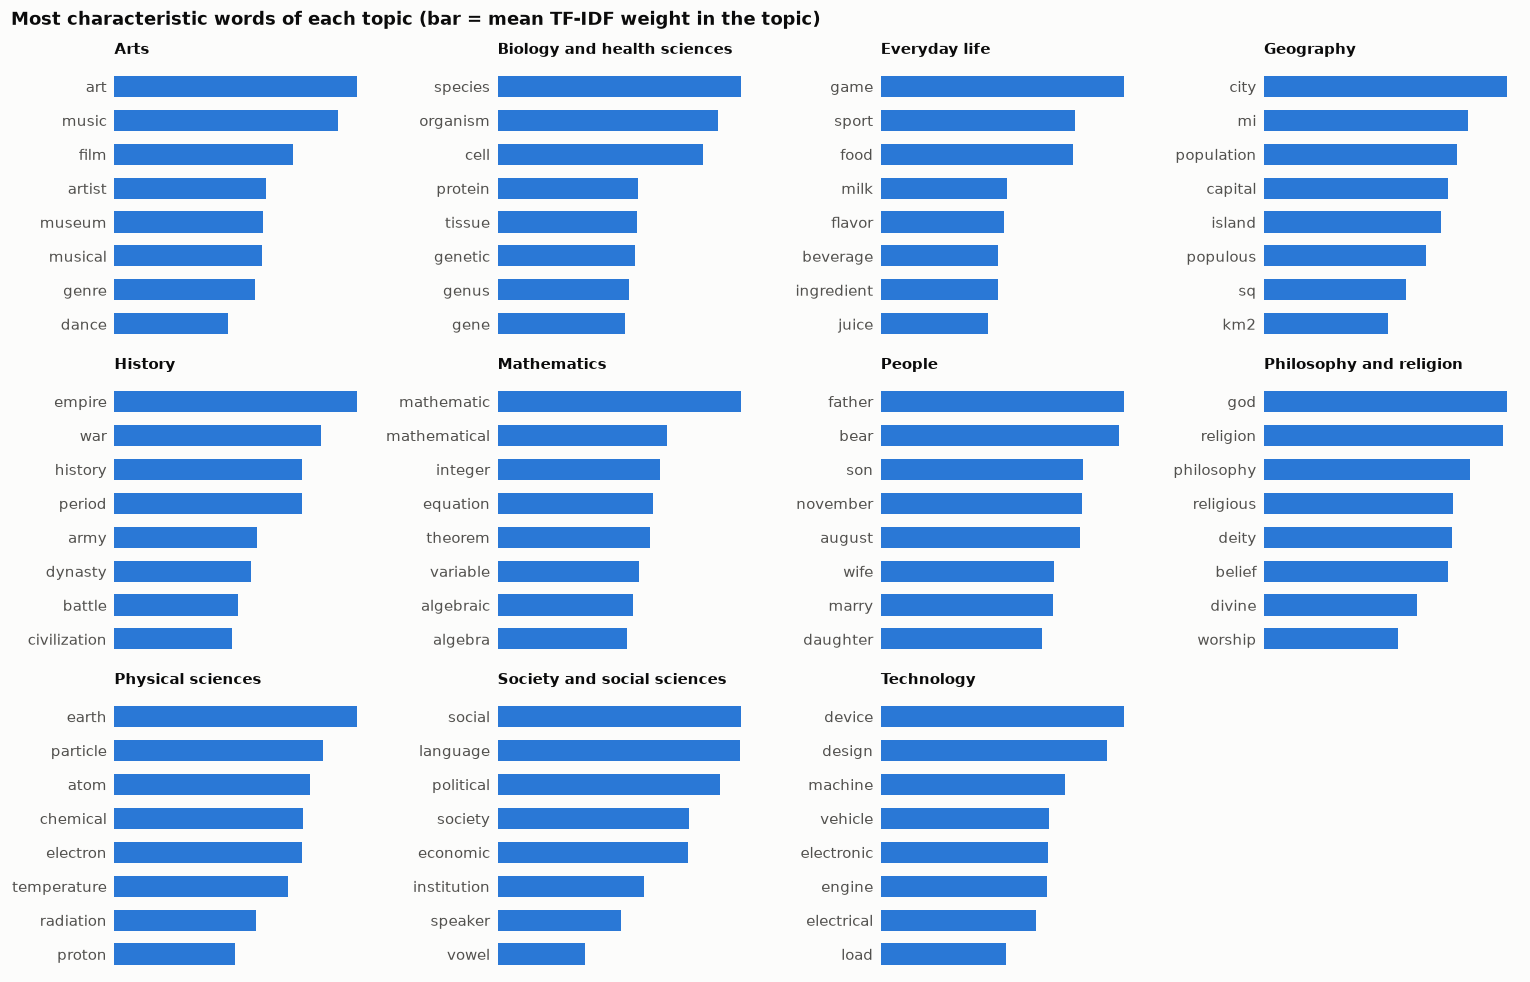

In [12]:
show(corpus.plot_topic_terms(model, 8), "topic_terms")

Each topic is recognisable from its words alone. Two artefacts of lemmatization show here: in *People*,
`bear` is the lemma of *born*, and in *Geography* `mi` and `sq` come from *sq mi*, the area unit.

### 4.3 Similarities between documents

Similarities among 2,000 random articles (about 2 million pairs), for each signal and for the combined
score $s$:

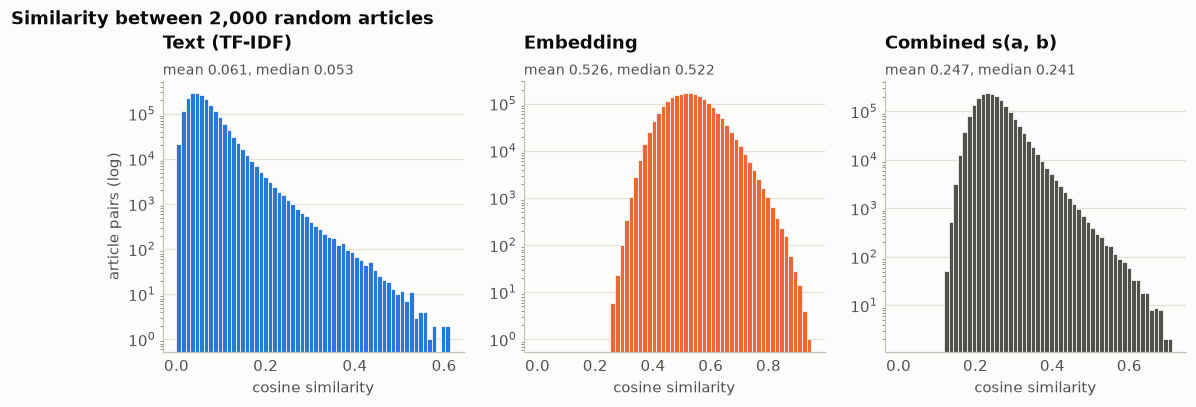

In [13]:
sample = corpus.similarity_sample(model, size=2000)
show(corpus.plot_similarity_distributions(sample), "similarity_distributions")

The two signals behave very differently. Text vectors are sparse, so most pairs of unrelated
articles share almost nothing. Embeddings are never far
apart: even unrelated articles have a cosine of about 0.5. The combined score therefore has a floor of
about 0.2 for unrelated articles, and good recommendations score roughly 0.4-0.6.

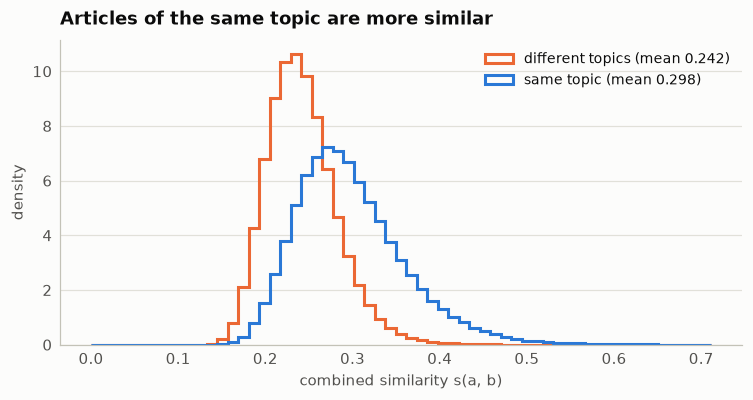

In [14]:
show(corpus.plot_same_vs_other_topic(sample), "same_vs_other_topic")

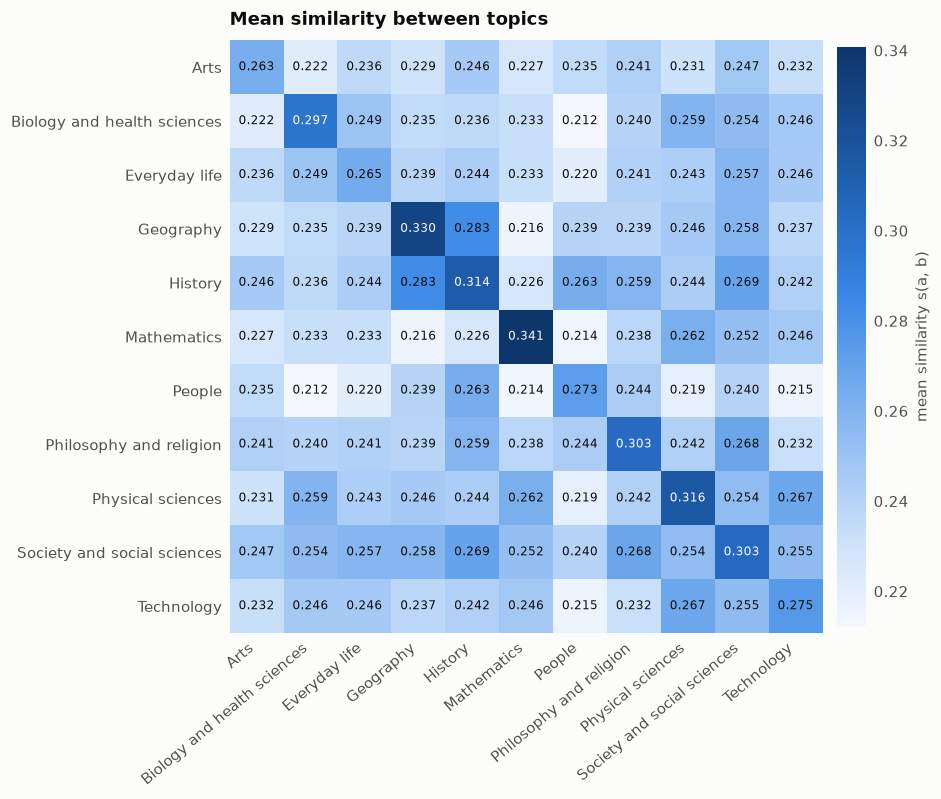

In [15]:
topics = corpus.topic_similarity_matrix(sample)
show(corpus.plot_topic_heatmap(topics), "topic_similarity")

Articles are most similar within their own topic (the diagonal). Mathematics is the most self-contained
topic. The strongest pair of different topics is Geography and History, followed by Mathematics and
Physical sciences: countries and empires, and the mathematics of physics.

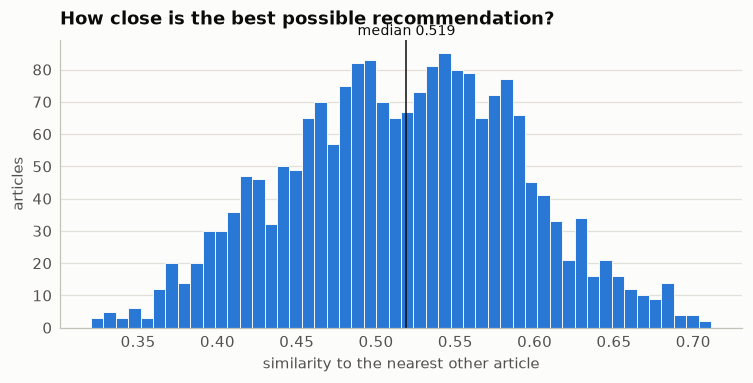

In [16]:
show(corpus.plot_nearest_neighbour(model, sample), "nearest_neighbour")

For almost every article the corpus holds a clearly related one, scoring well above the 0.2 floor of
unrelated pairs: the corpus is dense enough to recommend from.

### 4.4 A map of the corpus

A 2D t-SNE map of the embeddings of the 2,200 articles. Eleven topics are too many to tell apart by
color in one picture, so each panel highlights one topic over the whole map.

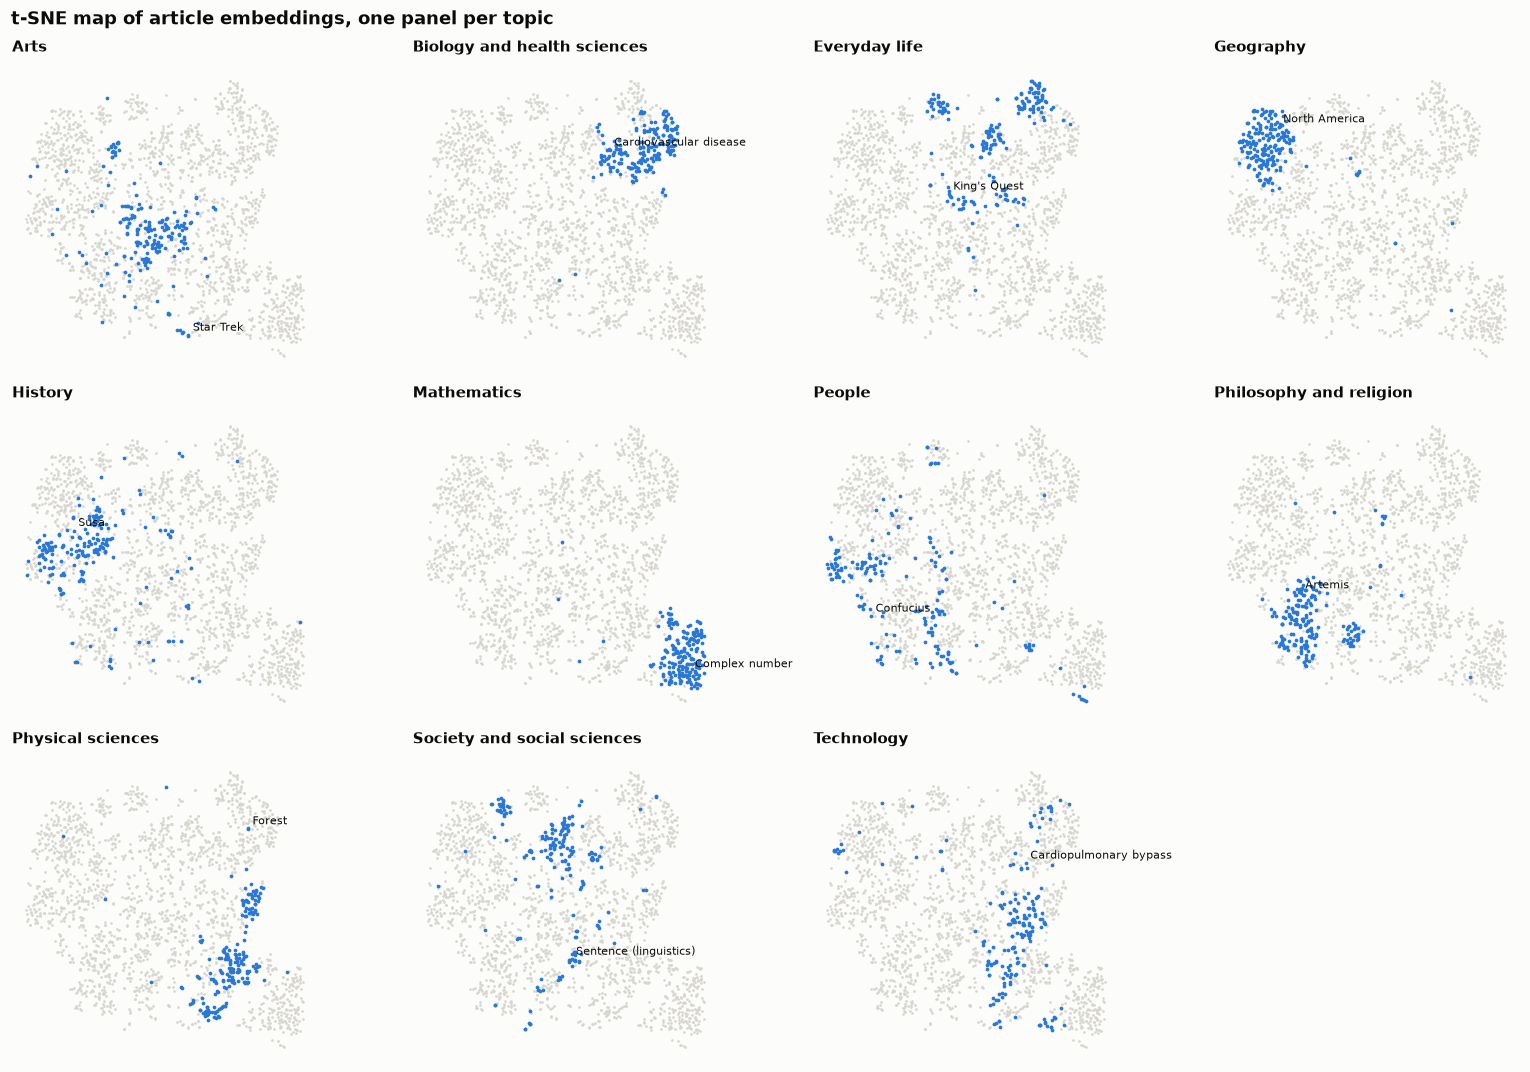

In [17]:
points = corpus.embedding_map(model, size=3000)
show(corpus.plot_embedding_map(points), "embedding_map")

Biology, Mathematics, Geography and Philosophy and religion form compact regions. People, History,
Society and Technology are spread out, because they touch every other subject: a biography of a
physicist sits next to physics, not next to other biographies.

## 5. Examples of recommendations, with explanations

### 5.1 One interest: popular music

Three visited articles about music, one given as a URL.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Visited: Jazz; Blues (fetched); Rock and roll

  #   Score  Title             Shared terms
  1   0.599  Rock music        blue, jazz, genre, roll
  2   0.525  Soul music        music, rhythm, african, genre
  3   0.495  Country music     music, category: music, guitar, genre
  4   0.469  Ragtime           ragtime, category: music, rhythm, jazz
  5   0.466  Music             category: music, music, rhythm, musical
  6   0.463  Folk music        music, category: music, genre, folk
  7   0.460  Pop music         music, category: music, genre, roll
  8   0.460  Hip-hop           genre, music, category: music, african
  9   0.452  Contemporary R&B  jazz, blue, category: music, rhythm
 10   0.449  Louis Armstrong   jazz, blue, genre, rhythm


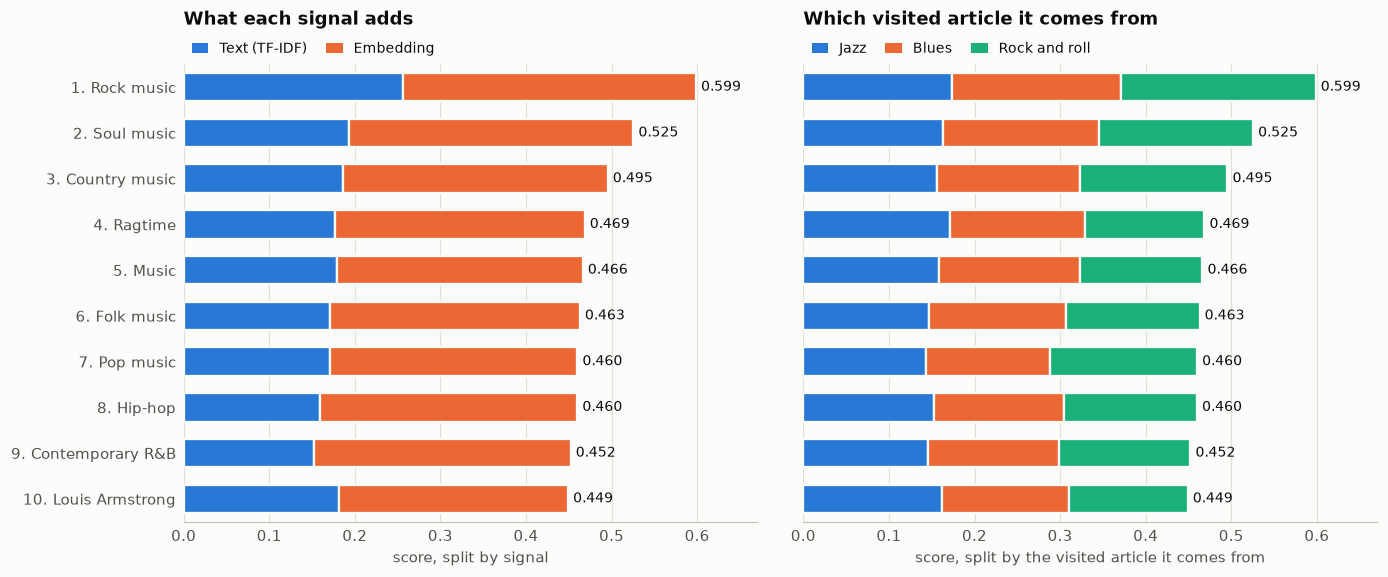

In [18]:
music = recommender.recommend(["Jazz", "Blues", "https://en.wikipedia.org/wiki/Rock_and_roll"], top_k=10)
print(music)
show(breakdown.explain_result(music), "example_music_result")

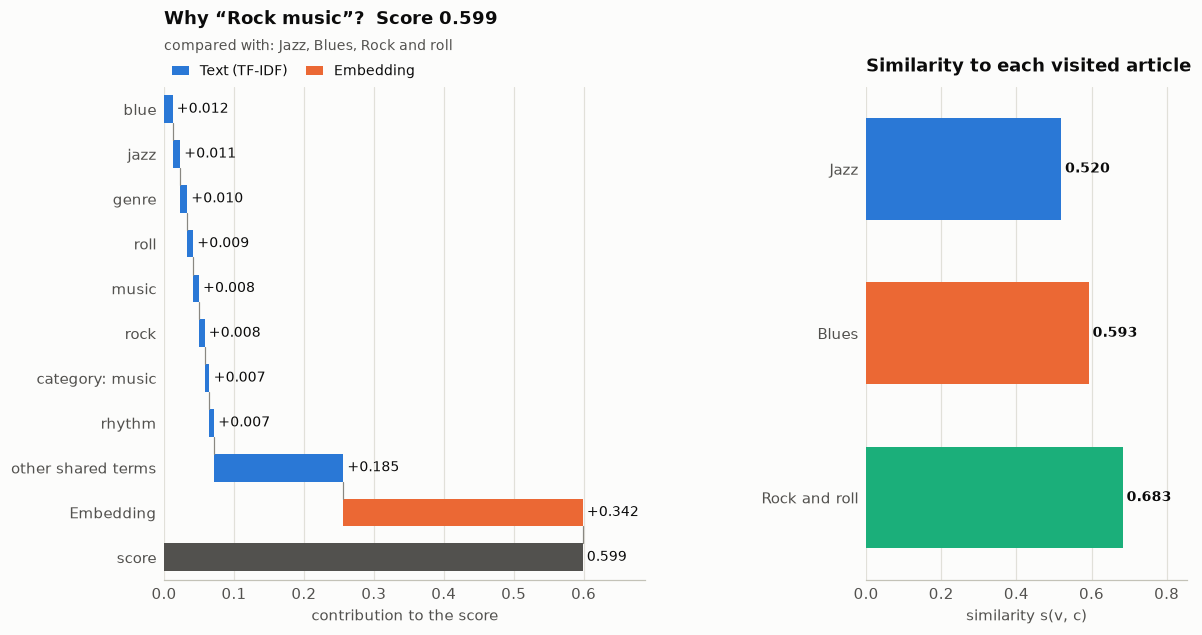

In [19]:
show(breakdown.explain(music, rank=1), "example_music_top")

All three visited articles form one interest, so every score is their mean similarity, and each
contributes about a third (right chart). The recommendations are the neighbouring genres. The waterfall
shows which shared words matter: `genre`, `blue` (the lemma of *blues*), `jazz`, `music`, `rock` and
`roll`. Most of the text part is spread over many smaller shared terms, and the embedding adds the
largest share.

### 5.2 Two interests: Ancient Rome and geometry

Visited: Ancient Rome; Julius Caesar; Pythagorean theorem (fetched); Euclid
Interests: Ancient Rome, Julius Caesar | Pythagorean theorem, Euclid

  #   Score  Title                   Shared terms
  1   0.561  Augustus                bc, roman, gaius, octavian
  2   0.532  Cicero                  bc, roman, rome, caesar
  3   0.502  Geometry                geometry, euclidean, geometer, mathematic
  4   0.470  Cleopatra               bc, cleopatra, roman, caesar
  5   0.464  Classical antiquity     bc, rome, roman, ad
  6   0.457  History of mathematics  geometry, mathematic, euclid, theorem
  7   0.443  Triangle                triangle, geometry, angle, euclidean
  8   0.442  Euclidean algorithm     euclid, euclidean, mathematician, theorem
  9   0.441  Trigonometry            triangle, angle, hypotenuse, mathematician
 10   0.440  History of Europe       bc, roman, empire, ad


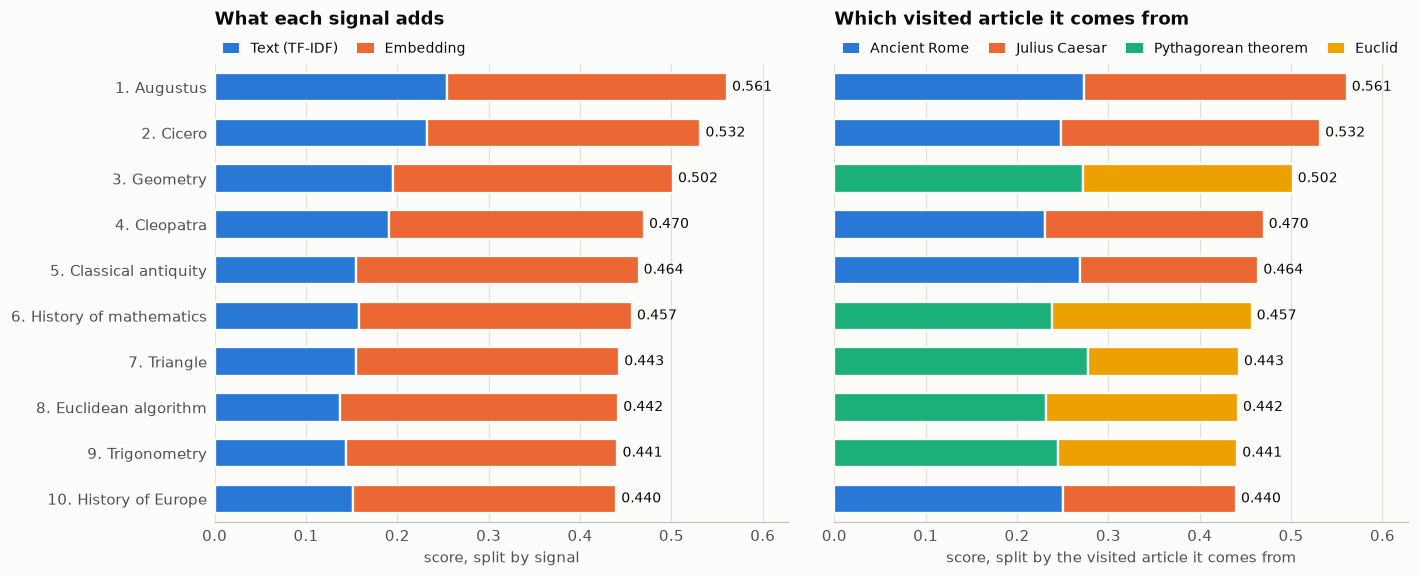

In [20]:
history = ["Ancient Rome", "Julius Caesar", "Pythagorean theorem", "Euclid"]
mixed = recommender.recommend(history, top_k=10)
print(mixed)
show(breakdown.explain_result(mixed), "example_mixed_result")

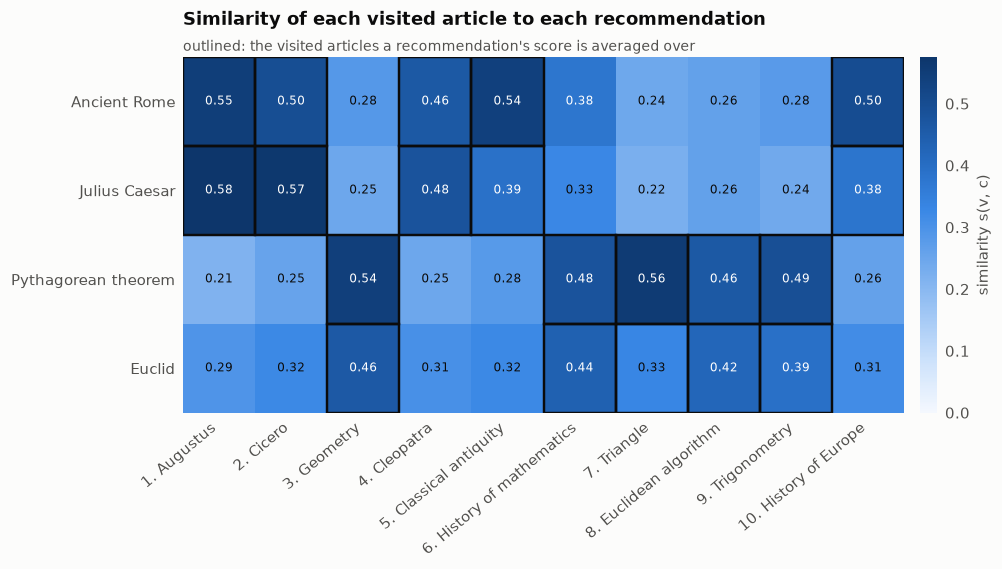

In [21]:
show(breakdown.plot_visited_heatmap(mixed), "example_mixed_heatmap")

The history is split into two interests, and both get recommendations. In the heatmap the outlined cells
are the visited articles each score is averaged over: Roman articles are scored only against *Ancient
Rome* and *Julius Caesar*, geometry articles only against *Pythagorean theorem* and *Euclid*. Compare
the plain mean over all four articles, which mixes both subjects into one profile:

In [22]:
mean = recommender.recommend(history, top_k=10, aggregation="power")
pd.DataFrame(
    {
        "interests (used)": [f"{r.title} ({r.score:.3f})" for r in mixed.recommendations],
        "plain mean": [f"{r.title} ({r.score:.3f})" for r in mean.recommendations],
    },
    index=range(1, 11),
)

,interests (used),plain mean
1,Augustus (0.561),Cicero (0.410)
2,Cicero (0.532),Augustus (0.408)
3,Geometry (0.502),History of mathematics (0.405)
4,Cleopatra (0.470),Geometry (0.383)
5,Classical antiquity (0.464),Classical antiquity (0.383)
6,History of mathematics (0.457),Cleopatra (0.372)
7,Triangle (0.443),Ancient Greece (0.370)
8,Euclidean algorithm (0.442),Ptolemaic Kingdom (0.366)
9,Trigonometry (0.441),History of Europe (0.363)
10,History of Europe (0.440),Archimedes (0.360)


The plain mean keeps only one pure geometry article (*Geometry*) in its top 10 and brings in articles that sit between the
two subjects, such as *History of mathematics* and *Ancient Greece*. Its scores are also lower, since every
candidate is compared with two visited articles from the other subject.

### 5.3 A niche subject: backgammon

A single visited article. The waterfall shows that the match goes beyond the word *game*: *dice*,
*board* and the name *backgammon* itself are shared.

Visited: Backgammon (fetched)

  #   Score  Title                 Shared terms
  1   0.534  Board game            dice, game, board, backgammon
  2   0.445  Game                  game, backgammon, dice, board
  3   0.439  Card game             game, category: game, player, tournament
  4   0.410  Horseshoes (game)     game, player, stake, category: game
  5   0.405  Curling               player, game, score, tournament
  6   0.402  Gambling              dice, backgammon, gambling, game
  7   0.391  Association football  player, game, play, category: game
  8   0.389  Repeated game         game, player, category: game, play


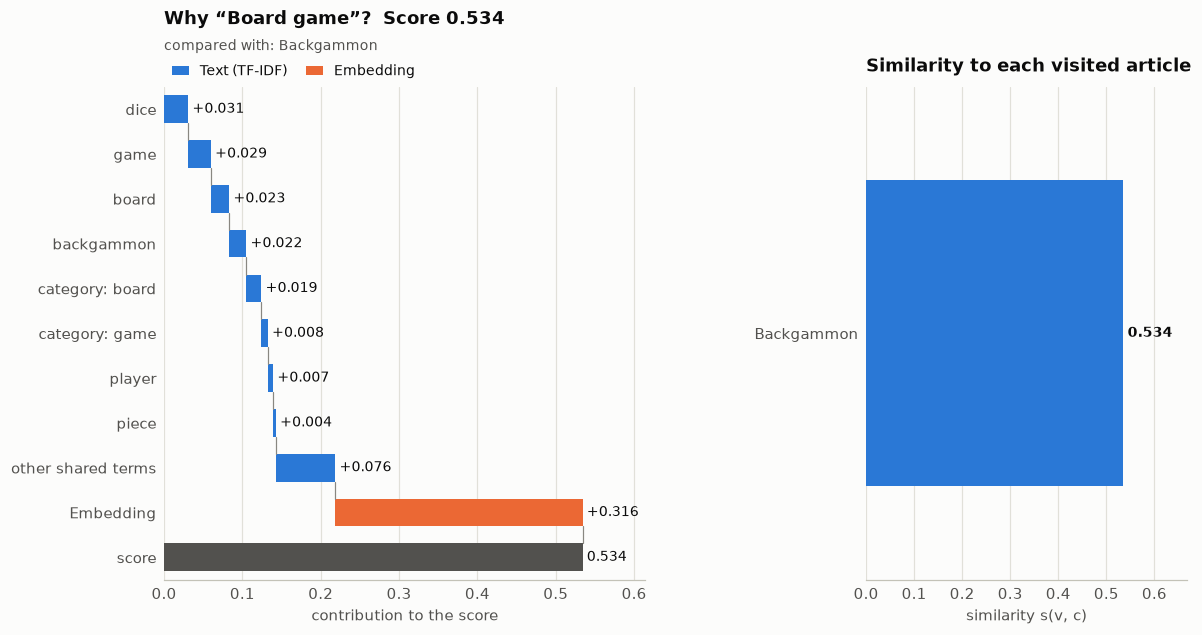

In [23]:
niche = recommender.recommend(["Backgammon"], top_k=8)
print(niche)
show(breakdown.explain(niche, rank=1), "example_niche_top")

### 5.4 An article outside the corpus

*Information retrieval* is not among the 2,200 articles. It is fetched from Wikipedia, extracted and
preprocessed exactly like the corpus (Stages 1 and 2), vectorized with the fitted model, and then used
like any visited article. Without internet access it is reported as unresolved instead.

Visited: Information retrieval (fetched); Search engine (fetched)

  #   Score  Title                    Shared terms
  1   0.443  Web browser              web, browser, user, query
  2   0.400  HTML                     web, browser, hyperlink, html
  3   0.390  Internet                 web, internet, hyperlink, user
  4   0.384  Artificial intelligence  search, software, google, user
  5   0.369  Computer science         information, algorithm, query, computer
  6   0.368  Google Cloud Platform    google, search, user, computing
  7   0.354  CSS                      web, browser, html, query
  8   0.352  Algorithm                search, algorithm, automate, datum


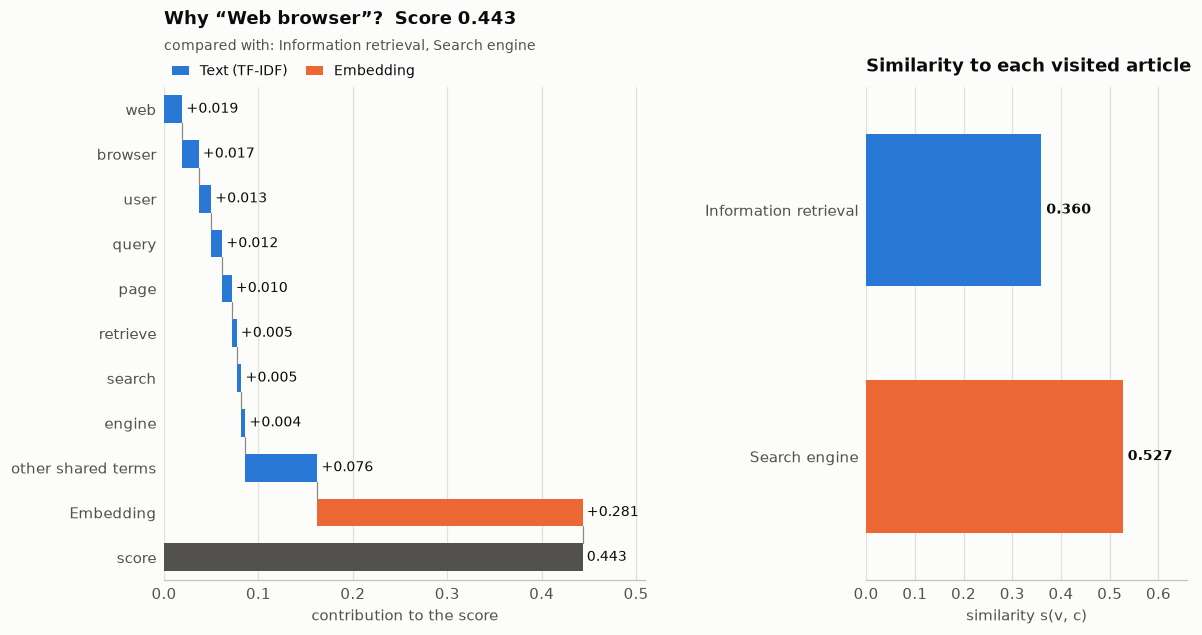

In [24]:
unseen = recommender.recommend(["Information retrieval", "Search engine"], top_k=8)
print(unseen)
if unseen.recommendations:
    show(breakdown.explain(unseen, rank=1), "example_unseen_top")

### 5.5 Inputs that cannot be used

Misspelled titles, disambiguation pages and URLs that are not Wikipedia articles are reported with the
reason and close titles; the remaining inputs are still used.

In [25]:
print(recommender.recommend(["Mercury", "Elektron", "https://example.com/page", "Dog"], top_k=5))

! Skipped 'Mercury': this is a disambiguation page; pick one of the meanings it lists. Did you mean: Mercury (planet), Memory?
! Skipped 'Elektron': this is a disambiguation page; pick one of the meanings it lists. Did you mean: Electron, Skeleton, Electronics?
! Skipped 'https://example.com/page': not an English Wikipedia article URL.
Visited: Dog

  #   Score  Title          Shared terms
  1   0.484  Cat            domesticate, category: animal, category: mammal, cat
  2   0.480  Horse          domesticate, breed, domesticated, domestication
  3   0.463  Mammal         category: mammal, ago, mammal, category: animal
  4   0.458  Sheep          category: mammal, domesticate, domesticated, category: animal
  5   0.444  Domestication  domestication, domesticate, dog, species


## 6. Evaluation and limitations

The signals, their weights and the aggregation were chosen with the same offline protocol as the text
representation (section 2): an article's recommendations count as related if they share its Vital
articles subsection or a held-out category. Settings were tuned on half of the articles and are reported
on the other half.

### 6.1 Signals

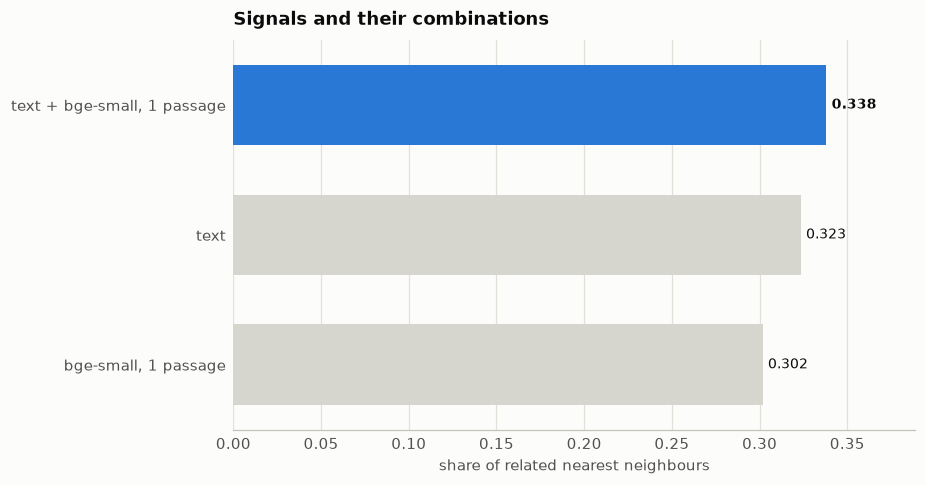

In [26]:
show(evaluation.plot_signal_eval(recommender_eval), "signal_eval")

In [27]:
signals = pd.DataFrame(recommender_eval["single_article_comparisons_on_test"]).T
signals.columns = ["difference", "95% low", "95% high"]
signals

,difference,95% low,95% high
"text + bge-small, 1 passage vs text",0.011,0.005,0.016
"text + bge-small, 1 passage vs bge-small, 1 passage",0.029,0.022,0.036


Text and embeddings together beat text alone by +0.011 and the embedding alone by +0.029.
bge-small beat MiniLM-L6, and embedding more than the first passage did not help once combined with text.

### 6.2 Aggregating a history

Simulated histories: one interest (3 or 5 articles of one subsection) or two interests (3 + 2 articles
from subsections of different topics). *Coverage* is the share of interests that get at least one
recommendation.

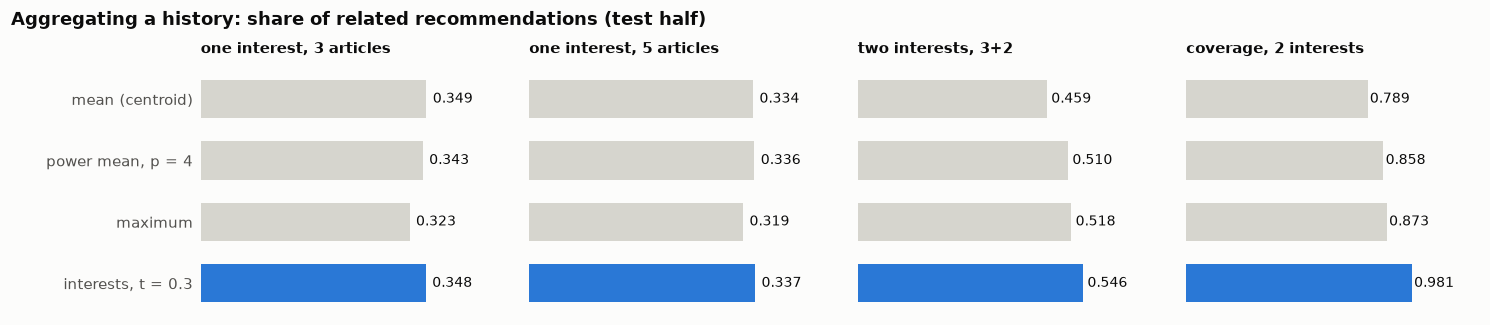

In [28]:
show(evaluation.plot_aggregation_eval(recommender_eval), "aggregation_eval")

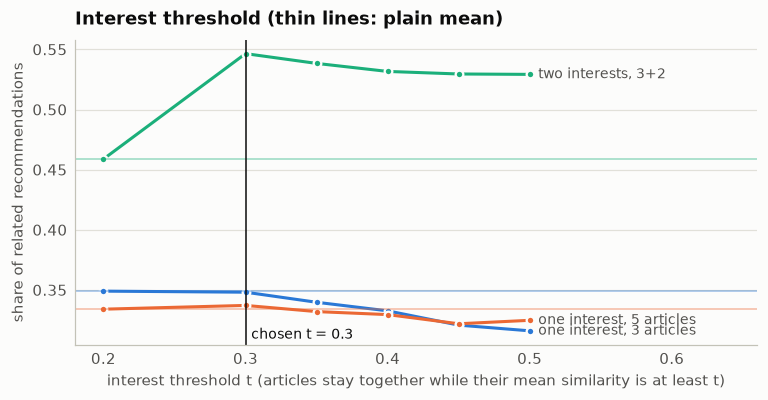

In [29]:
show(evaluation.plot_interest_threshold(recommender_eval), "interest_threshold")

Splitting a history into interests costs almost nothing when it has one topic (−0.001) and gains +0.088
over the mean when it has two; it also serves 98 % of the interests instead of 79 %. A threshold of 0.3
is the best trade-off: lower values merge unrelated interests, higher values split one interest apart.

### 6.3 Limitations

* **Scores are relative.** Because embeddings never drop far below 0.5, unrelated articles still score
  about 0.2. A score is meaningful compared with other scores, not as an absolute probability.
* **The corpus bounds the answers.** Recommendations come only from the 2,200 articles; an article
  fetched on the fly can be visited, but is never recommended.
* **Relevance is approximated.** Subsections and categories are a proxy for what a reader finds
  related; they do not reward surprising but useful recommendations.
* **No diversity re-ranking.** Within one interest, near-duplicates (e.g. *Roman Republic* and *Roman
  Empire*) can both appear.